<div class="alert alert-block alert-success">
    
# Task 3 in Assessment 1
## **Student Team: 12**

#### **Students:**
##### [teammate], ID: [removed]
##### Akhmad Fauzi Nurulhamzah ID: [removed]


Date: 24/10/2025


Environment: Python 3.13.7

    
</div>

<div class="alert alert-block alert-danger">
    
## Table of Contents

</div>    

[1. Introduction](#Intro) <br>
[2. Importing Libraries](#libs) <br>
[3. Examining Raw Data(given input file from task1)](#examine1) <br>
[4. Examining metadata](#examine2) <br>
[5. Analysis](#DA) <br>
    - [5.1 Rating Distribution](#A51) <br>
    - [5.2 Timeseries Analysis](#A52) <br>
    - [5.3 Most Common Phrase in Review](#A53) <br>
    - [5.4 Attach Image Effect](#A54) <br>
    - [5.5 Rating Distribution](#A55) <br>
[6. Summary](#summary) <br>
[7. References](#Ref) <br>

<div class="alert alert-block alert-warning">

## 1.  Introduction  <a class="anchor" name="Intro"></a>
    
</div>

In this task, we conduct a Data Audit, data preparation such as data validation, cleaning, data enginering and finally do a comprehensive exploratory data analysis (EDA) on the provided Amazon product review data result from task 1 (json data). The goal is to uncover interesting insights that can be useful for further analysis or decision-making.

<div class="alert alert-block alert-warning">
    
## 2.  Importing Libraries  <a class="anchor" name="libs"></a>
 </div>

The packages to be used in this assessment are imported in the following. They are used to fulfill the following tasks:

* **json**: to read, parse, and write JSON files
* **pandas**: to handle, clean, and analyze tabular data using DataFrame structures, including reading data from files, transforming columns, and performing aggregations.
* **numpy**: perform fast numerical and mathematical operations
* **matplotlib.pyplot**: to create data visualizations for exploratory data analysis.
* **seaborn**: to produce aesthetically appealing and statistically informative plots built on top of matplotlib, simplifying the creation of complex visualizations like boxplots, heatmaps, and distribution plots.
* **datetime (from the datetime module)**: to parse, manipulate, and format date and time information
* **ast**: to safely evaluate strings containing Python literal structures (e.g., lists or dictionaries) into their corresponding Python objects
* **os**: interact with the operating system, including navigating directories, checking file existence, and handling file paths.
* **CountVectorizer:** to convert a collection of text documents into a matrix of token counts for text analysis
* **TextBlob**: to perform basic natural language processing tasks such as sentiment analysis and polarity detection
* **sns**: to create attractive and informative statistical visualizations easily
* **plt**: to build and customize plots and charts using Matplotlib


In [34]:
#@title 2.1 Import libraries
#Standard imports
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import ast
import os
from sklearn.feature_extraction.text import CountVectorizer
from textblob import TextBlob
import seaborn as sns
import matplotlib.pyplot as plt

#plotting defaults
%matplotlib inline
plt.rcParams['figure.figsize'] = (10,5)
sns.set(style='whitegrid')

In [35]:
#@title 2.2 Mounting to Gdrive
#Mount drive (run once)
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


This step is to mount  Google Drive to the Colab environment using the google.colab library. This process will allows to access datasets and save output files directly to my Drive, ensuring data persistence across sessions. By executing drive.mount('/content/drive'), Drive storage became accessible under the /content/drive directory, enabling seamless integration between Google Drive and the Colab workspace.

<div class="alert alert-block alert-warning">

## 3.  Examining Raw Data(given input file from task1) <a class="anchor" name="examine1"></a>

 </div>

This step is to load and examine the raw dataset that we have from task 1 and check its initial quality. First, we load the data from gdrive and displayed the first few rows using df.head() to understand the structure and content. Next, performed a missing value audit with df.isna().sum() to identify any incomplete data. Finally, checked for duplicate rows using df.duplicated().sum() to ensure data integrity before moving to further cleaning and analysis.

In [36]:
#@title 3.1 Load Dataset


#Load CSV file
csv_path = "/content/drive/MyDrive/student_group012/task1_012.csv"
df_csv = pd.read_csv(csv_path)
print(f"CSV file loaded successfully with shape: {df_csv.shape}")

#Load JSON file
json_path = "/content/drive/MyDrive/student_group012/task1_012.json"
with open(json_path, "r", encoding="utf-8") as f:
    data = json.load(f)



#latten JSON structure to create a DataFrame
all_reviews = []
for parent_product_id, product_data in data.items():
    reviews = product_data.get("reviews", [])
    for review in reviews:
        #Store the main product ID in a new column
        review["parent_product_id"] = parent_product_id
        all_reviews.append(review)

df_json = pd.DataFrame(all_reviews)
print(f"JSON file loaded and flattened successfully with shape: {df_json.shape}")

#Optional: merge or compare both datasets

print(df_json.info())
print(df_csv.info())


CSV file loaded successfully with shape: (138756, 3)
JSON file loaded and flattened successfully with shape: (265208, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265208 entries, 0 to 265207
Data columns (total 11 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   category              265208 non-null  object
 1   reviewer_id           265208 non-null  object
 2   rating                265208 non-null  object
 3   review_title          265208 non-null  object
 4   review_text           265208 non-null  object
 5   attached_images       265208 non-null  object
 6   product_id            265208 non-null  object
 7   review_timestamp      265208 non-null  object
 8   is_verified_purchase  265208 non-null  object
 9   helpful_votes         265208 non-null  object
 10  parent_product_id     265208 non-null  object
dtypes: object(11)
memory usage: 22.3+ MB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138756 

In [37]:
df_json.head()

,category,reviewer_id,rating,review_title,review_text,attached_images,product_id,review_timestamp,is_verified_purchase,helpful_votes,parent_product_id
0,automotive,ah6xl4y4muysgv5hdin4jhxn2dlq,5.0,five stars,good book.,none,0440224764,2018-10-04 17:08:25,true,0,0440224764
1,automotive,aemnba6ox4xnyvl6jqhmumrjdunq,4.0,four stars,fun to do,none,0486475468,2018-03-10 20:49:01,true,0,0486475468
2,automotive,af3dguv2fbjhcmwpm7wl33z37x2q,5.0,unplug and have a little fun,coloring is not just for kids any more. this i...,none,0486475468,2016-01-15 05:40:25,true,0,0486475468
3,automotive,afoknkexixvuussqrdxjdwmsnwuq,5.0,beautiful designs for an adult rediscovering t...,these are lovely designs even before any color...,none,0486475468,2015-01-26 01:34:36,true,1,0486475468
4,automotive,agg3d3vnbvrqou7v6m724b4l35za,5.0,great book,covers everything i needed,none,0892877073,2022-08-13 00:38:11,true,0,0892877073


In [38]:
df = pd.merge(df_json, df_csv, on='parent_product_id', how='left')

print(f"Merged dataset shape: {df.shape}")
print(df[['parent_product_id', 'rating', 'review_count', 'review_text_count']].head())


Merged dataset shape: (265208, 13)
  parent_product_id rating  review_count  review_text_count
0        0440224764    5.0             1                  1
1        0486475468    4.0             3                  3
2        0486475468    5.0             3                  3
3        0486475468    5.0             3                  3
4        0892877073    5.0             1                  1


In [39]:
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265208 entries, 0 to 265207
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   category              265208 non-null  object
 1   reviewer_id           265208 non-null  object
 2   rating                265208 non-null  object
 3   review_title          265208 non-null  object
 4   review_text           265208 non-null  object
 5   attached_images       265208 non-null  object
 6   product_id            265208 non-null  object
 7   review_timestamp      265208 non-null  object
 8   is_verified_purchase  265208 non-null  object
 9   helpful_votes         265208 non-null  object
 10  parent_product_id     265208 non-null  object
 11  review_count          265208 non-null  int64 
 12  review_text_count     265208 non-null  int64 
dtypes: int64(2), object(11)
memory usage: 26.3+ MB


In [40]:
#@title 3.2 View dataset
df.head()


,category,reviewer_id,rating,review_title,review_text,attached_images,product_id,review_timestamp,is_verified_purchase,helpful_votes,parent_product_id,review_count,review_text_count
0,automotive,ah6xl4y4muysgv5hdin4jhxn2dlq,5.0,five stars,good book.,none,0440224764,2018-10-04 17:08:25,true,0,0440224764,1,1
1,automotive,aemnba6ox4xnyvl6jqhmumrjdunq,4.0,four stars,fun to do,none,0486475468,2018-03-10 20:49:01,true,0,0486475468,3,3
2,automotive,af3dguv2fbjhcmwpm7wl33z37x2q,5.0,unplug and have a little fun,coloring is not just for kids any more. this i...,none,0486475468,2016-01-15 05:40:25,true,0,0486475468,3,3
3,automotive,afoknkexixvuussqrdxjdwmsnwuq,5.0,beautiful designs for an adult rediscovering t...,these are lovely designs even before any color...,none,0486475468,2015-01-26 01:34:36,true,1,0486475468,3,3
4,automotive,agg3d3vnbvrqou7v6m724b4l35za,5.0,great book,covers everything i needed,none,0892877073,2022-08-13 00:38:11,true,0,0892877073,1,1


From the dataset head view we can see that the dataset contains customer review information for automotive products. Each record represents one product review and included details in column such as:

*   **category** - the product category being reviewed (e.g., automotive).
*   **reviewer_id** - a unique anonymous ID assigned to the reviewer.
*   **rating** - the numeric score given by the reviewer, usually on a 1-5 scale.
*   **review_title** - a short title summarizing the reviewer's opinion.
*   **review_text** - the detailed written review or comment from the customer.
*   **attached_images**  indicates whether any images were attached to the review (e.g., “none” or image links).
*   **product_id** - a unique identifier for the specific product reviewed.
*   **review_timestamp** - the date and time when the review was posted.
*   **is_verified_purchase** - shows whether the reviewer actually bought the product (“true” means verified).
*   **helpful_votes** - the number of users who marked the review as helpful.
*   **parent_product_id** - the main or original product ID that groups related products or versions together


In [41]:
#@title 3.3 Check Missing Data and Duplicates

#Check null values
print("Missing Value Count")
print(df.isna().sum())

# Check duplicated rows
print("\n Duplicate Row Count")
print(df.duplicated().sum())



Missing Value Count
category                0
reviewer_id             0
rating                  0
review_title            0
review_text             0
attached_images         0
product_id              0
review_timestamp        0
is_verified_purchase    0
helpful_votes           0
parent_product_id       0
review_count            0
review_text_count       0
dtype: int64

 Duplicate Row Count
0


From the missing value check and duplicates check result it can be seen that there are no missing values in any columns and no duplicate rows in the dataset.

Fromb all previous review all sample entries show valid and complete data, indicating that the dataset is well-structured and ready for further analysis such as rating trends, sentiment analysis, or product performance evaluation.

<div class="alert alert-block alert-warning">

## 4.  Examining Metadata <a class="anchor" name="examine2"></a>

 </div>

In [42]:
# @title 4.1 Check data types
#check metadata
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265208 entries, 0 to 265207
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   category              265208 non-null  object
 1   reviewer_id           265208 non-null  object
 2   rating                265208 non-null  object
 3   review_title          265208 non-null  object
 4   review_text           265208 non-null  object
 5   attached_images       265208 non-null  object
 6   product_id            265208 non-null  object
 7   review_timestamp      265208 non-null  object
 8   is_verified_purchase  265208 non-null  object
 9   helpful_votes         265208 non-null  object
 10  parent_product_id     265208 non-null  object
 11  review_count          265208 non-null  int64 
 12  review_text_count     265208 non-null  int64 
dtypes: int64(2), object(11)
memory usage: 26.3+ MB


**Initial Observations:**

The data show that we have dataset contains 265,208 rows (records) and 11 columns (variables). Every data type is still in the object form, and we need to do adjutment for some column:
* **rating, helpful_votes, and review_timestamp** need to be converted to numeric and datetime formats, respectively.
* **is_verified_purchase** should be converted to a boolean.

In [43]:
#@title 4.2 Data Correction
#convert data type

#Convert numeric data
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
df['helpful_votes'] = pd.to_numeric(df['helpful_votes'], errors='coerce')

#Convert 'rating' to integer
df['rating'] = df['rating'].astype(int)


#Convert review_timestamp
df['review_timestamp'] = pd.to_datetime(df['review_timestamp'], errors='coerce')


#Convert 'is_verified_purchase' to a boolean type
df['is_verified_purchase'] = df['is_verified_purchase'].apply(lambda x: True if str(x).lower() == 'true' else False)

#verify
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265208 entries, 0 to 265207
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   category              265208 non-null  object        
 1   reviewer_id           265208 non-null  object        
 2   rating                265208 non-null  int64         
 3   review_title          265208 non-null  object        
 4   review_text           265208 non-null  object        
 5   attached_images       265208 non-null  object        
 6   product_id            265208 non-null  object        
 7   review_timestamp      265208 non-null  datetime64[ns]
 8   is_verified_purchase  265208 non-null  bool          
 9   helpful_votes         265208 non-null  int64         
 10  parent_product_id     265208 non-null  object        
 11  review_count          265208 non-null  int64         
 12  review_text_count     265208 non-null  int64         
dtyp

After the data conversion, the updated data types become:

*  **category, reviewer_id, review_title, review_text, attached_images, product_id, parent_product_id**: remain as object because they contain text data.
*  **review_count, and review_text_count** still in numeric format (int64)
*   **rating and helpful_votes**: now have the correct numeric format (int64), enabling mathematical and statistical operations
*   **review_timestamp**: has been successfully converted to a datetime64[ns] type, allowing time-based analysis such as monthly or yearly trends.

*   **is_verified_purchase**: has been correctly changed into a Boolean (bool) type, indicating True for verified purchases and False for unverified ones.

In [44]:
#@title 4.3. Feature Engineering

#Assuming 'none' means no review text, we'll treat it as 0 length.
df['review_length'] = df['review_text'].apply(lambda x: 0 if x.lower() == 'none' else len(x.split()))

print("\nNew 'review_length' feature value counts:")
print(df['review_length'].value_counts())

#Extract year from 'review_year' for easier analysis
df['review_year'] = df['review_timestamp'].dt.year

print("\nNew 'review_year' feature value counts:")
print(df['review_year'].value_counts())

#Create a new boolean column 'has_image'
#inspect the 'attached_images' column
print("Original values in 'attached_images':")
print(df['attached_images'].value_counts().head())

#Based on the output, 'none' (as a string) means no images. Any other string (likely a URL or file list) means images are present.

df['has_image'] = df['attached_images'].apply(lambda x: False if (not isinstance(x, str) or x.lower() == 'none') else True)

print("\nNew 'has_image' feature value counts:")
print(df['has_image'].value_counts())



New 'review_length' feature value counts:
review_length
2      15609
4       9544
5       9496
6       9182
7       8481
       ...  
591        1
627        1
585        1
911        1
564        1
Name: count, Length: 700, dtype: int64

New 'review_year' feature value counts:
review_year
2019    36070
2021    35869
2022    33369
2020    33136
2018    28356
2017    25715
2016    25470
2015    19762
2014    11419
2023     6740
2013     5685
2012     1945
2011      906
2010      439
2009      145
2008      103
2007       66
2006       10
2005        3
Name: count, dtype: int64
Original values in 'attached_images':
attached_images
none                                                                                                                                                                                                                                                                                                                                                                      

In [45]:
# @title 4.5. Validity (Value Ranges)
print("\n--- Value Validity Audit ---")

print("\nRating Stats:")
# Our 'rating' column is now an integer, so value_counts is best
print(df['rating'].value_counts().sort_index())
is_rating_valid = all(df['rating'].between(1, 5))
print(f"All ratings between 1 and 5: {is_rating_valid}")

print("\nHelpful Votes Stats:")
print(df['helpful_votes'].describe())
is_votes_valid = all(df['helpful_votes'] >= 0)
print(f"All helpful votes >= 0: {is_votes_valid}")

print("\nReview Timestamp Stats:")
# --- THIS IS THE FIX ---
# We just remove (datetime_is_numeric=True)
print(df['review_timestamp'].describe())

# This next line will now work correctly
is_timestamp_valid = all(df['review_timestamp'] < pd.Timestamp.now())
print(f"All timestamps in the past: {is_timestamp_valid}")


--- Value Validity Audit ---

Rating Stats:
rating
1     21585
2     10272
3     16770
4     32194
5    184387
Name: count, dtype: int64
All ratings between 1 and 5: True

Helpful Votes Stats:
count    265208.000000
mean          0.804738
std           6.614768
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max        1811.000000
Name: helpful_votes, dtype: float64
All helpful votes >= 0: True

Review Timestamp Stats:
count                           265208
mean     2019-01-14 09:39:01.931321856
min                2005-03-01 16:09:27
25%                2017-01-05 12:52:09
50%                2019-05-31 02:50:32
75%      2021-04-11 04:28:43.750000128
max                2023-03-22 02:50:14
Name: review_timestamp, dtype: object
All timestamps in the past: True


### 4.6 Final Data for Analysis

In [46]:
#@title 4.6.1 Final Metadata For analysis

#final metadata
df.info()

#data view
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265208 entries, 0 to 265207
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   category              265208 non-null  object        
 1   reviewer_id           265208 non-null  object        
 2   rating                265208 non-null  int64         
 3   review_title          265208 non-null  object        
 4   review_text           265208 non-null  object        
 5   attached_images       265208 non-null  object        
 6   product_id            265208 non-null  object        
 7   review_timestamp      265208 non-null  datetime64[ns]
 8   is_verified_purchase  265208 non-null  bool          
 9   helpful_votes         265208 non-null  int64         
 10  parent_product_id     265208 non-null  object        
 11  review_count          265208 non-null  int64         
 12  review_text_count     265208 non-null  int64         
 13 

,category,reviewer_id,rating,review_title,review_text,attached_images,product_id,review_timestamp,is_verified_purchase,helpful_votes,parent_product_id,review_count,review_text_count,review_length,review_year,has_image
0,automotive,ah6xl4y4muysgv5hdin4jhxn2dlq,5,five stars,good book.,none,0440224764,2018-10-04 17:08:25,True,0,0440224764,1,1,2,2018,False
1,automotive,aemnba6ox4xnyvl6jqhmumrjdunq,4,four stars,fun to do,none,0486475468,2018-03-10 20:49:01,True,0,0486475468,3,3,3,2018,False
2,automotive,af3dguv2fbjhcmwpm7wl33z37x2q,5,unplug and have a little fun,coloring is not just for kids any more. this i...,none,0486475468,2016-01-15 05:40:25,True,0,0486475468,3,3,24,2016,False
3,automotive,afoknkexixvuussqrdxjdwmsnwuq,5,beautiful designs for an adult rediscovering t...,these are lovely designs even before any color...,none,0486475468,2015-01-26 01:34:36,True,1,0486475468,3,3,130,2015,False
4,automotive,agg3d3vnbvrqou7v6m724b4l35za,5,great book,covers everything i needed,none,0892877073,2022-08-13 00:38:11,True,0,0892877073,1,1,4,2022,False


The final dataset contains 265,208 reviews and 14 columns, representing cleaned and enriched information about customer reviews for automotive products. This is a description of each column:

*   **category** - the product category being reviewed (e.g., automotive).
*   **reviewer_id** - a unique anonymous ID assigned to the reviewer.
*   **rating** - the numeric score given by the reviewer, usually on a 1-5 scale
*   **review_title** - a short title summarizing the reviewer's opinion.
*   **review_text** - the detailed written review or comment from the customer.
*   **attached_images**  indicates whether any images were attached to the review (e.g., “none” or image links)
*   **product_id** - a unique identifier for the specific product reviewed.
*   **review_timestamp** - the date and time when the review was posted.
*   **is_verified_purchase** - shows whether the reviewer actually bought the product (“true” means verified)
*   **helpful_votes** - the number of users who marked the review as helpful.
*   **parent_product_id** - the main or original product ID that groups related products or versions together
*   **review_length** -	New feature showing the total number of characters or words in the review text.
*   **review_year** -	Extracted year from the review timestamp for time-based analysis.
*   **has_image** -	Boolean field indicating whether the review includes an image attachment
*   **review_count**: the number of total reviews for a parent product ID. - output format: int
*   **review_text_count**: the number of reviews that contains a text (excluding 'none')

In [47]:
#@title 4.6.2 Descriptive statistic

print("\n Descriptive Statistics")
print(df.describe())


 Descriptive Statistics
              rating               review_timestamp  helpful_votes  \
count  265208.000000                         265208  265208.000000   
mean        4.310390  2019-01-14 09:39:01.931321856       0.804738   
min         1.000000            2005-03-01 16:09:27       0.000000   
25%         4.000000            2017-01-05 12:52:09       0.000000   
50%         5.000000            2019-05-31 02:50:32       0.000000   
75%         5.000000  2021-04-11 04:28:43.750000128       0.000000   
max         5.000000            2023-03-22 02:50:14    1811.000000   
std         1.244821                            NaN       6.614768   

        review_count  review_text_count  review_length    review_year  
count  265208.000000      265208.000000  265208.000000  265208.000000  
mean       11.543030          11.529354      34.093742    2018.536707  
min         1.000000           0.000000       0.000000    2005.000000  
25%         1.000000           1.000000       7.000000  

**Descriptive Statistics Insight**

From the descriptive statistics, we can observe that most **customers tend to give high ratings**, with an average **score of 4.31 out of 5**. This shows a generally positive sentiment toward the products. Only a small portion of reviews have low ratings (as low as 1), which indicates that negative experiences exist but are not dominant. The relatively low standard deviation of 1.24 suggests that **ratings are quite consistent across reviewers**, meaning there are no extreme variations in customer satisfaction levels.

The reviews cover a long time span, **from 2005 to 2023**, with most activity happening around 2018 to 2019. This pattern suggests that the dataset captures customer opinions over an extended period, will allowing us to analyze changes in review behavior or sentiment over time.

The helpful_votes column shows that most reviews receive little to no interaction from other users, with an average of less than one helpful vote per review. However, a small number of reviews received a large number of helpful votes (up to 1,811), showing that some reviews are particularly useful or detailed to other customers.

In terms of content, most reviews are short and direct, averaging around 34 words, although a few reach over 2,000 words. The wide variation in review length indicates that while most users prefer to write brief comments, some are more expressive and take time to share detailed feedback.

Overall, these statistics show that the dataset is diverse, containing a mix of short and long reviews, recent and old submissions, and varying levels of engagement — making it suitable for deeper analysis on customer satisfaction and behavior patterns.

<div class="alert alert-block alert-warning">

## **5.  Analysis** <a class="anchor" name="DA"></a>

 </div>

In this step, we perform Exploratory Data Analysis (EDA) to gain a deeper understanding of the dataset. The goal is to identify patterns, trends, and relationships within the data that can provide meaningful insights about customer behavior and product performance. Through various visualizations and statistical summaries, we aim to uncover how different factors such as rating, review length, helpful votes, and verification status relate to each other.

in this analysis we performed

**5.1 Product Performance Analysis**:Perfomed frequency distribution plot (bar chart) to visualize the overall customer satisfaction profile and identify characteristic patterns then do quadrant plot that segments products into four strategic groups based on average rating versus review count. This segmentation will provides a clear, prioritized view of the catalog

**5.2. Timeseries Analysis**: To understand temporal patterns, the reviewTime column will be converted to datetime objects. The data was then aggregated by different time intervals (year-month, month of year, and hour of day) to plot trend lines for both total review count and average rating over time. This methodology was used to identify seasonal peaks (e.g., holiday shopping) and daily customer feedback patterns.

**5.3 Common Phrase Analysis**: Deployed a Bag-of-Words text mining approach using CountVectorizer. This was configured to extract 2-word phrases (bi-grams) and remove English stop words. This method was run separately on 1-star and 5-star reviews to find the most frequent phrases for dissatisfaction and satisfaction.

**5.4. Review Feature Analysis (Image Effect)**: Conducted a comparative group analysis by creating a binary 'has_image' column. Performed a groupby on this column to calculate the average helpful votes and average rating for reviews with and without images, determining the impact of images on these metrics.

**5.5. Sentiment-to-Rating Correlation**: Performed lexicon-based sentiment analysis using TextBlob to get a polarity score for each review. These scores were categorized into positive, negative, and neutral, and a crosstab heatmap was generated to compare the text sentiment against the given 1-5 star rating.



In [48]:
df.head()

,category,reviewer_id,rating,review_title,review_text,attached_images,product_id,review_timestamp,is_verified_purchase,helpful_votes,parent_product_id,review_count,review_text_count,review_length,review_year,has_image
0,automotive,ah6xl4y4muysgv5hdin4jhxn2dlq,5,five stars,good book.,none,0440224764,2018-10-04 17:08:25,True,0,0440224764,1,1,2,2018,False
1,automotive,aemnba6ox4xnyvl6jqhmumrjdunq,4,four stars,fun to do,none,0486475468,2018-03-10 20:49:01,True,0,0486475468,3,3,3,2018,False
2,automotive,af3dguv2fbjhcmwpm7wl33z37x2q,5,unplug and have a little fun,coloring is not just for kids any more. this i...,none,0486475468,2016-01-15 05:40:25,True,0,0486475468,3,3,24,2016,False
3,automotive,afoknkexixvuussqrdxjdwmsnwuq,5,beautiful designs for an adult rediscovering t...,these are lovely designs even before any color...,none,0486475468,2015-01-26 01:34:36,True,1,0486475468,3,3,130,2015,False
4,automotive,agg3d3vnbvrqou7v6m724b4l35za,5,great book,covers everything i needed,none,0892877073,2022-08-13 00:38:11,True,0,0892877073,1,1,4,2022,False


<div class="alert alert-block alert-warning">

### 5.1 Rating Distributions <a class="anchor" name="A51"></a>

 </div>



/tmp/ipython-input-230927111.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='rating', data=df, palette='viridis', order=[5, 4, 3, 2, 1])


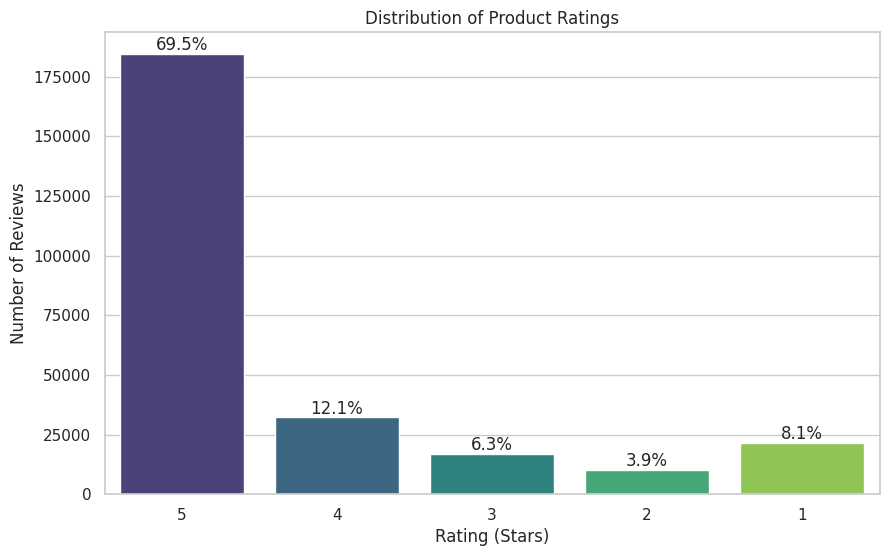

In [49]:

plt.figure(figsize=(10, 6))
sns.countplot(x='rating', data=df, palette='viridis', order=[5, 4, 3, 2, 1])

#Calculate percentages
total = len(df)
ax = plt.gca()
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom')

plt.title('Distribution of Product Ratings') #show title
plt.xlabel('Rating (Stars)')
plt.ylabel('Number of Reviews')
plt.show()

# Display the value counts
#print(df['rating'].value_counts(normalize=True).sort_index(ascending=False))

**Insight**

The 5-star rating is completely dominant. At 69.5%, nearly seven out of every ten reviews are perfect scores. This single bar is dramatically taller than all the other categories combined, showing strong customer satisfaction.

An interesting pattern emerges at the bottom of the scale. The number of reviews does not decrease smoothly. Instead, it drops to its lowest point at 2 stars (3.9%) and then rises again for 1-star reviews (8.1%).

This J-shaped curve is common. It indicates that people are most motivated to leave a review when they either love the product (5 stars) or strongly dislike it (1 star). Neutral or mildly negative (2 and 3-star) opinions are shared far less often. The 1-star rating is the third most common review, more frequent than both 2-star and 3-star ratings.


Calculating product performance statistics

Using custom Quality Threshold: 3.0 (on Median Rating)
Using Median Review Count as Popularity Line: 7.0

Products categorized into quadrants:
quadrant
Top Performer            4655
Hidden Gem               3146
Niche/New (Low Rated)      86
Product at Risks           52
Name: count, dtype: int64


/tmp/ipython-input-362387285.py:36: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stats_filtered['quadrant'] = stats_filtered.apply(



Plot saved as 'product_quadrant_analysis_median.png'


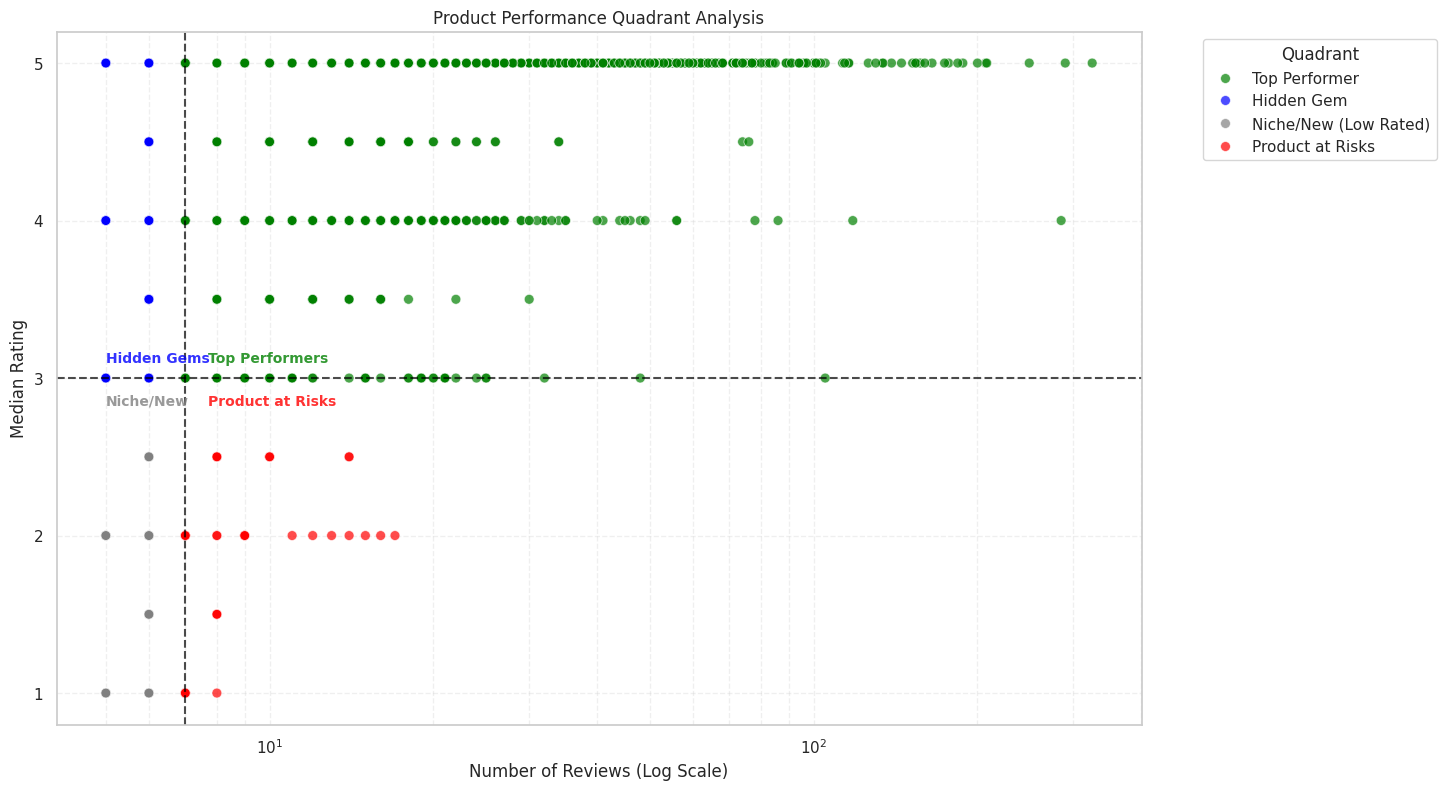

In [50]:
#@title 5.1.1 Product Performance Quadrant Analysis


#Calculate Product Performance Statistics (using MEDIAN)
print("\nCalculating product performance statistics")
product_stats = df.groupby('parent_product_id').agg(
    review_count=('rating', 'count'),
    median_rating=('rating', 'median') #Using median as it's robust to skew
).reset_index()

#Define Quadrants (Custom 3.0 Threshold)
#Filter for products with a meaningful number of reviews
stats_filtered = product_stats[product_stats['review_count'] >= 5]

if not stats_filtered.empty:
    #User-defined "Quality" line
    quality_threshold = 3.0
    print(f"\nUsing custom Quality Threshold: {quality_threshold} (on Median Rating)")

    #create "Popularity" line (Median of counts)
    median_review_count = stats_filtered['review_count'].median()
    print(f"Using Median Review Count as Popularity Line: {median_review_count}")

    #define a function to categorize products
    def assign_quadrant(row, quality_line, popularity_line):
        if row['median_rating'] >= quality_line and row['review_count'] >= popularity_line:
            return 'Top Performer'
        elif row['median_rating'] >= quality_line and row['review_count'] < popularity_line:
            return 'Hidden Gem'
        elif row['median_rating'] < quality_line and row['review_count'] >= popularity_line:
            return 'Product at Risks'
        else:
            return 'Niche/New (Low Rated)'

    #Apply function
    stats_filtered['quadrant'] = stats_filtered.apply(
        assign_quadrant,
        args=(quality_threshold, median_review_count),
        axis=1
    )

    print("\nProducts categorized into quadrants:")
    print(stats_filtered['quadrant'].value_counts())



    #create visuaization
    # Visualize the Quadrant Analysis
    plt.figure(figsize=(14, 9))
    ax = sns.scatterplot(
        data=stats_filtered,
        x='review_count',
        y='median_rating',
        hue='quadrant',
        palette={'Top Performer':'green', 'Hidden Gem':'blue', 'Product at Risks':'red', 'Niche/New (Low Rated)':'grey'},
        alpha=0.7,
        s=50
    )

    #Add the quadrant lines
    ax.axhline(quality_threshold, ls='--', color='black', alpha=0.7)
    ax.axvline(median_review_count, ls='--', color='black', alpha=0.7)

    #Set y-axis to discrete steps (1, 2, 3, 4, 5)
    ax.set_yticks([1, 2, 3, 4, 5])

    ax.set_xscale('log')
    plt.title('Product Performance Quadrant Analysis')
    plt.xlabel('Number of Reviews (Log Scale)')
    plt.ylabel('Median Rating')
    plt.legend(title='Quadrant', bbox_to_anchor=(1.05, 1), loc=2)
    plt.grid(True, which="both", ls="--", alpha=0.3)

    #Add labels
    plt.text(median_review_count * 1.1, quality_threshold + 0.1, 'Top Performers',
             fontsize=10, color='green', fontweight='bold', alpha=0.8)
    plt.text(stats_filtered['review_count'].min(), quality_threshold + 0.1, 'Hidden Gems',
             fontsize=10, color='blue', fontweight='bold', alpha=0.8)
    plt.text(median_review_count * 1.1, quality_threshold - 0.1, 'Product at Risks',
             fontsize=10, color='red', fontweight='bold', alpha=0.8, va='top')
    plt.text(stats_filtered['review_count'].min(), quality_threshold - 0.1, 'Niche/New',
             fontsize=10, color='grey', fontweight='bold', alpha=0.8, va='top')

    plt.savefig("product_quadrant_analysis_median.png")
    print("\nPlot saved as 'product_quadrant_analysis_median.png'")
    plt.show()

else:
    print("\nNo products found with >= 5 reviews. Skipping quadrant analysis.")

**Insight**

Based on the output from Product quadrant analysis we have exact numbers:

*   Top Performers: 4655 products
*   Hidden Gem: 3146 products
*   Niche/New: 86 products
*   Product at Risk: 52 products

it means that we can prioritized to-do list:

*  1st Priority is "Product at Risks" (52 products), This is a list of popular products that are consistently disappointing customers. and the **action plan** is to follow up to QA team for needs this list to improve/fix the product

*  Next Priority is "Hidden Gems" (3146 products): This is a list of products that customers love, but few people are buying. the **action plan** for this is we can follow up this to marketing team to make more or better marketing

*  Then the "Top Performers" (4655 products): These are the product stars. **The action** here is to protect them and ensure their quality never slips.

*  Last, "Niche/New" (86 products): This group can be monitored, but they are not an urgent priority.


In [51]:
#@title 5.1.2 Top 3 Products per Quadrant

#define Quadrants (Custom 3.0 Threshold)
stats_filtered = product_stats[product_stats['review_count'] >= 5]

if not stats_filtered.empty:
    quality_threshold = 3.0
    median_review_count = stats_filtered['review_count'].median()

    #Define the quadrant function
    def assign_quadrant(row, quality_line, popularity_line):
        if row['median_rating'] >= quality_line and row['review_count'] >= popularity_line:
            return 'Top Performer'
        elif row['median_rating'] >= quality_line and row['review_count'] < popularity_line:
            return 'Hidden Gem'
        elif row['median_rating'] < quality_line and row['review_count'] >= popularity_line:
            return 'Product at Risk'
        else:
            return 'Niche/New (Low Rated)'

    #Apply the function to create the 'quadrant' column
    stats_filtered['quadrant'] = stats_filtered.apply(
        assign_quadrant,
        args=(quality_threshold, median_review_count),
        axis=1
    )

    print(f"\nTotal products in each quadrant (review_count >= 5):")
    print(stats_filtered['quadrant'].value_counts())

    #Get Top 3 from Each Quadrant

    #'Top Performers' -> Sorted by highest review_count
    top_performers = stats_filtered[
        stats_filtered['quadrant'] == 'Top Performer'
    ].sort_values(by='review_count', ascending=False)

    print("\n Top 3 'Top Performers' ")
    print(top_performers.head(3))

    #'Hidden Gems' -> Sorted by highest median_rating (to find the best)
    hidden_gems = stats_filtered[
        stats_filtered['quadrant'] == 'Hidden Gem'
    ].sort_values(by='median_rating', ascending=False)

    print("\n Top 3 'Hidden Gems' (Highest Rated) ")
    print(hidden_gems.head(3))

    #'Product at Risk' -> Sorted by highest review_count (to find biggest problems)
    at_risks = stats_filtered[
        stats_filtered['quadrant'] == 'Product at Risk'
    ].sort_values(by='review_count', ascending=False)

    print("\n Top 3 'Quality Risks' (Most Popular Problems) ")
    print(at_risks.head(3))

    # 'Niche/New (Low Rated)' -> Sorted by highest review_count (most visible of this group)
    niche_low_rated = stats_filtered[
        stats_filtered['quadrant'] == 'Niche/New (Low Rated)'
    ].sort_values(by='review_count', ascending=False)

    print("\n Top 3 'Niche/New (Low Rated)' (Most Reviewed) ")
    print(niche_low_rated.head(3))

else:
    print("\nNo products found with >= 5 reviews. Skipping analysis.")


Total products in each quadrant (review_count >= 5):
quadrant
Top Performer            4655
Hidden Gem               3146
Niche/New (Low Rated)      86
Product at Risk            52
Name: count, dtype: int64

 Top 3 'Top Performers' 
       parent_product_id  review_count  median_rating       quadrant
136571        b0bzxx3ryr           325            5.0  Top Performer
125054        b09hz3w89w           290            5.0  Top Performer
138003        b0c7czxbbt           285            4.0  Top Performer

 Top 3 'Hidden Gems' (Highest Rated) 
       parent_product_id  review_count  median_rating    quadrant
138746        b0cgzk1jjz             6            5.0  Hidden Gem
31            b00004rb1t             6            5.0  Hidden Gem
53            b00007e7lo             5            5.0  Hidden Gem

 Top 3 'Quality Risks' (Most Popular Problems) 
      parent_product_id  review_count  median_rating         quadrant
4110         b000c5cekc            17            2.0  Product at Ri

/tmp/ipython-input-762331278.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stats_filtered['quadrant'] = stats_filtered.apply(


Deep dive into finding top 3 product resulted:


1.   Among **Top Performers**, products **b0bzxx3ryr, b09hz3w89w, and b0c7czxbbt **lead with hundreds of reviews and strong median ratings (4.0 - 5.0). These are proven favorites with consistent customer satisfaction and may showcased as benchmark products

1.   For **Hidden Gems**, items **b0cgzk1jjz, b00004rb1t, and b00007e7lo** each hold perfect 5.0 ratings but have fewer than 10 reviews. They deliver excellent quality but low visibility, suggesting great potential for promotion or feature placement.

1.   In contrast, in the **Products at Risk**, there are **b000c5cekc, b001jt5tqq, and b00f91b4le** they have relatively high review volumes but low median ratings (around 2.0), signaling recurring issues that need immediate attention.

1.   Lastly,** Niche or New Low-Rated products** like **b0015d88u0, b000bqqwr8, and b006b376wk** also receive low ratings despite small review counts, indicating early-stage performance concerns worth monitoring.

/tmp/ipython-input-3516471008.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='std_dev_rating', y='parent_product_id', data=top_5_divisive,


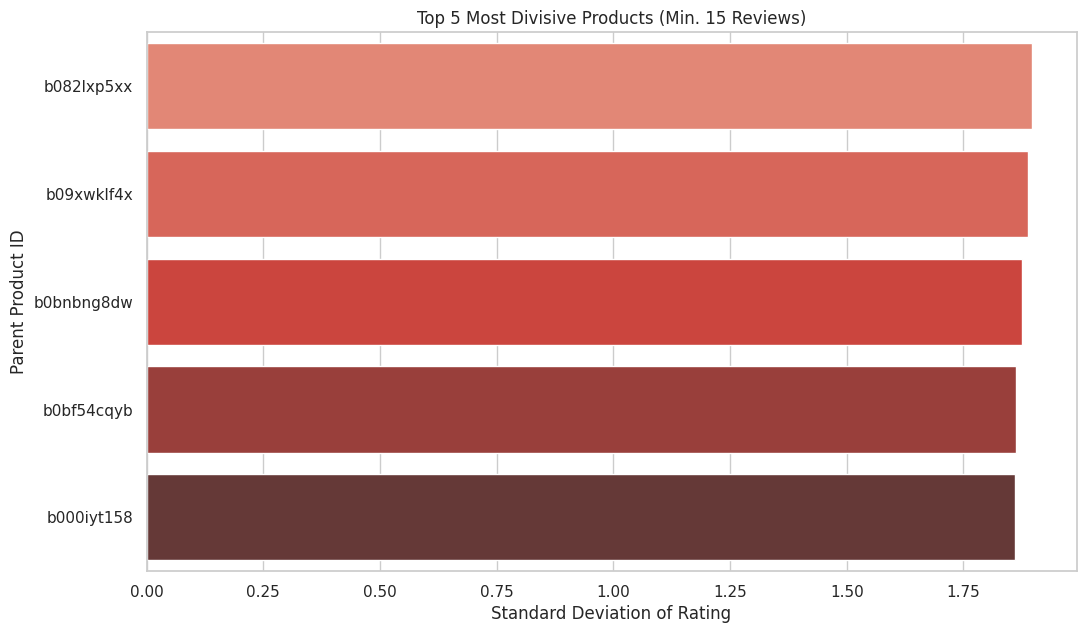


 Top 5 Most Divisive Products 
       parent_product_id  mean_rating  std_dev_rating  review_count
107958        b082lxp5xx     3.200000        1.897367            15
128648        b09xwklf4x     3.045455        1.889250            22
134272        b0bnbng8dw     3.076923        1.874526            26
132545        b0bf54cqyb     3.705882        1.862951            17
9267          b000iyt158     3.250000        1.860249            20


In [52]:
#@title 5.1.3 Finding Divisive Products (by Rating Standard Deviation)

# Group by the 'parent_product_id' to analyze each product
product_stats = df.groupby('parent_product_id').agg(
    review_count=('rating', 'count'),
    mean_rating=('rating', 'mean'),
    std_dev_rating=('rating', 'std')
).reset_index()

#We must filter for products with a meaningful number of reviews
#A product with one 5-star and one 1-star review would have a high std dev, but it's not statistically significant.
min_reviews = 15  # Set a threshold
product_stats_filtered = product_stats[product_stats['review_count'] >= min_reviews].copy()

#Fill any NaNs in std_dev_rating (for products with all same-star reviews) with 0
product_stats_filtered['std_dev_rating'] = product_stats_filtered['std_dev_rating'].fillna(0)

#visualize the most divisive products
top_5_divisive = product_stats_filtered.nlargest(5, 'std_dev_rating')

plt.figure(figsize=(12, 7))
sns.barplot(x='std_dev_rating', y='parent_product_id', data=top_5_divisive,
            palette='Reds_d', orient='h')
plt.title(f'Top 5 Most Divisive Products (Min. {min_reviews} Reviews)')
plt.xlabel('Standard Deviation of Rating')
plt.ylabel('Parent Product ID')
plt.show()


print("\n Top 5 Most Divisive Products ")
print(top_5_divisive[['parent_product_id', 'mean_rating', 'std_dev_rating', 'review_count']].head())

**Insight**

in this step we plan to check the divisive of the product which is the  splits of customer opinion to the product. We plan to measure this by calculating the Standard Deviation of the ratings for each product. A high standard deviation indicates that the ratings are widely spread out from the average (highly divisive), whereas a low standard deviation means the ratings are tightly clustered together (a consensus).

This output shows **top 5 most divisive products**, as it correctly filters for items with a meaningful number of reviews (10 or more). These are genuinely show polarizing "love-it-or-hate-it" products. The #1 item, b082lxp5xx, perfectly illustrates this: its mediocre 3.2 average rating is highly misleading because its high standard deviation (1.897) proves this average isn't from consistent 3-star ratings, but rather from a "battle" between customers giving it 5-star and 1-star reviews.

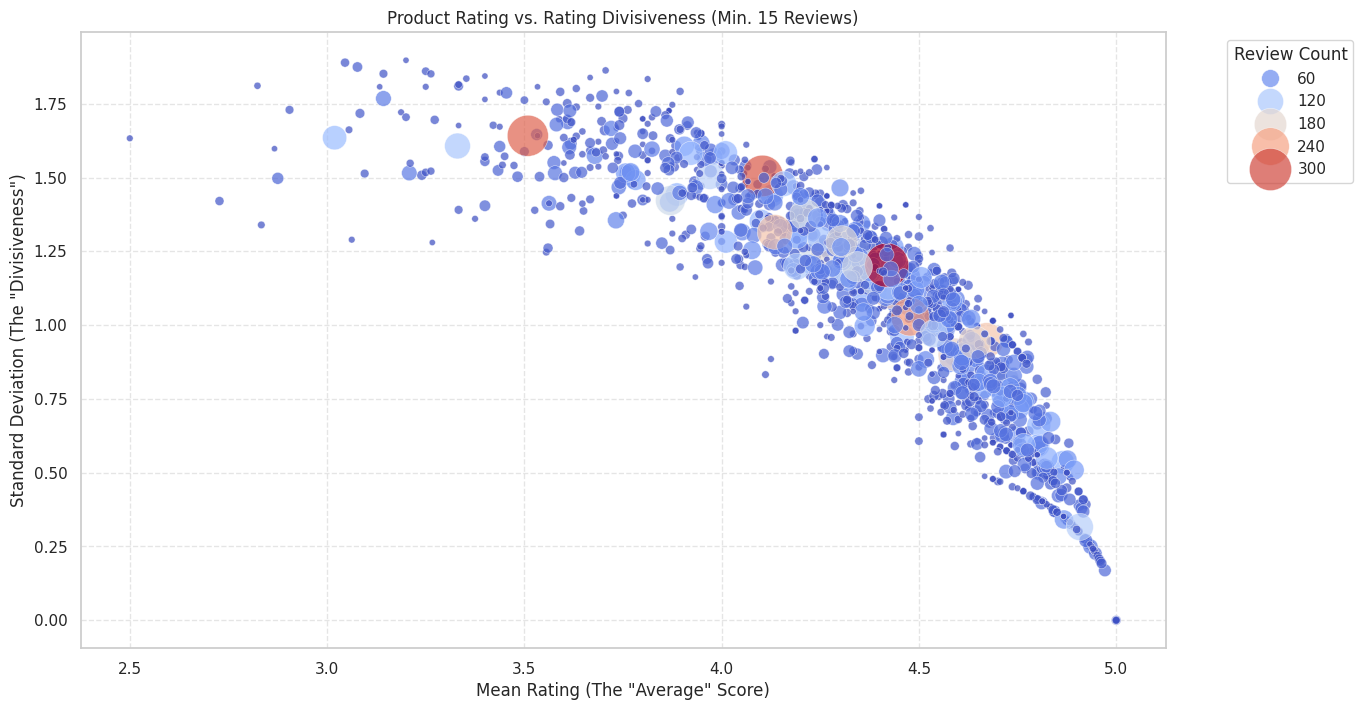

In [53]:
#Scatter plot of all products
plt.figure(figsize=(14, 8))
sns.scatterplot(x='mean_rating', y='std_dev_rating',
                data=product_stats_filtered,
                size='review_count',  # Size bubbles by number of reviews
                hue='review_count',  # Color bubbles by number of reviews
                palette='coolwarm',
                alpha=0.7,
                sizes=(20, 1000)) # Range of bubble sizes

plt.title(f'Product Rating vs. Rating Divisiveness (Min. {min_reviews} Reviews)')
plt.xlabel('Mean Rating (The "Average" Score)')
plt.ylabel('Standard Deviation (The "Divisiveness")')
plt.legend(title='Review Count', bbox_to_anchor=(1.05, 1), loc=2)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

**Insight**

This chart reveals an "arch of disagreement," **showing a clear relationship between a product's average score and how controversial its reviews are.** Products with very high (near 5.0) or very low (near 1.0) average ratings have low divisiveness, meaning customers are in strong agreement that the items are either great or terrible. The most "divisive" products—those that people either love or hate—are found in the middle. These items have average scores between 3.0 and 4.0 but have the highest disagreement, indicating they receive a strong mix of both 1-star and 5-star reviews.

Looking closer, the dots cluster into three groups: the "crowd-pleasers" (high average, low disagreement), the "clear losers" (low average, low disagreement), and the "mixed bag" (mid-range average, high disagreement). The size and color of the dots show that the most-reviewed products are not always the best. While many popular items are in the "crowd-pleaser" group, several of the largest dots are right at the peak of the arch, confirming that some of the most popular products are also the most polarizing.

<div class="alert alert-block alert-warning">

### 5.2 Timeseries Analysis <a class="anchor" name="A52"></a>

 </div>



/tmp/ipython-input-1630251470.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=valid_years, palette='mako')


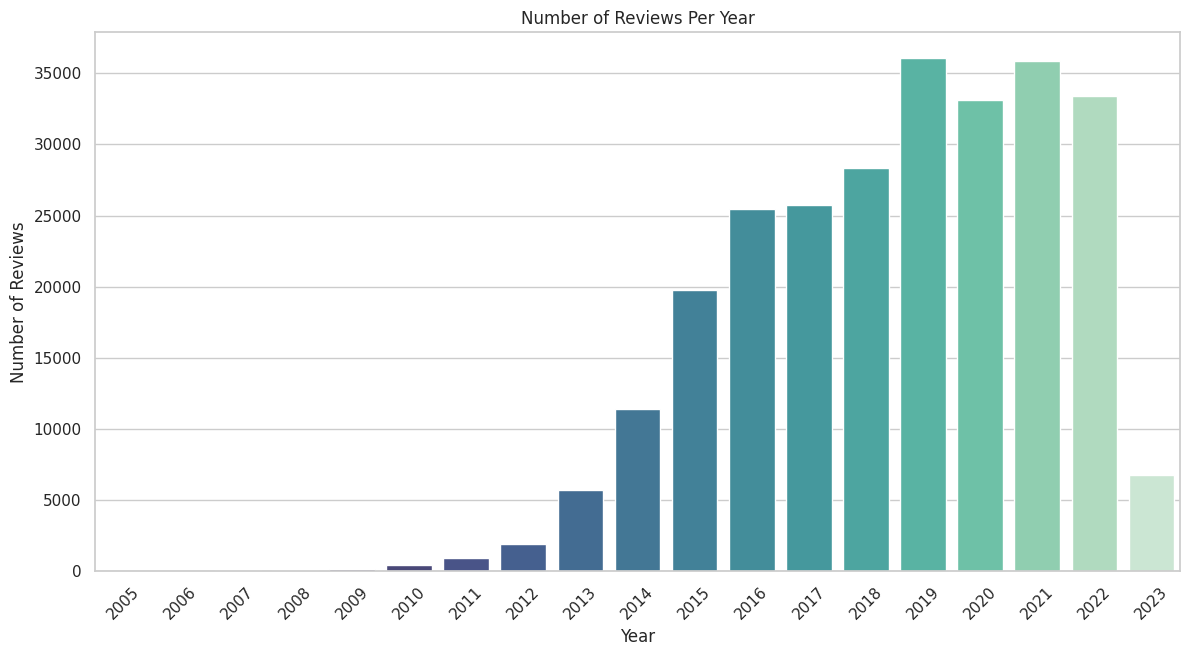

In [54]:
# @title 5.2.1 Reviews Per Year
# We will filter out any potential erroneous years (e.g., far in the future or past)
valid_years = df['review_year'].dropna().astype(int)
valid_years = valid_years[(valid_years > 2000) & (valid_years <= 2025)]

plt.figure(figsize=(14, 7))
sns.countplot(x=valid_years, palette='mako')
plt.title('Number of Reviews Per Year')
plt.xlabel('Year')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=45)
plt.show()

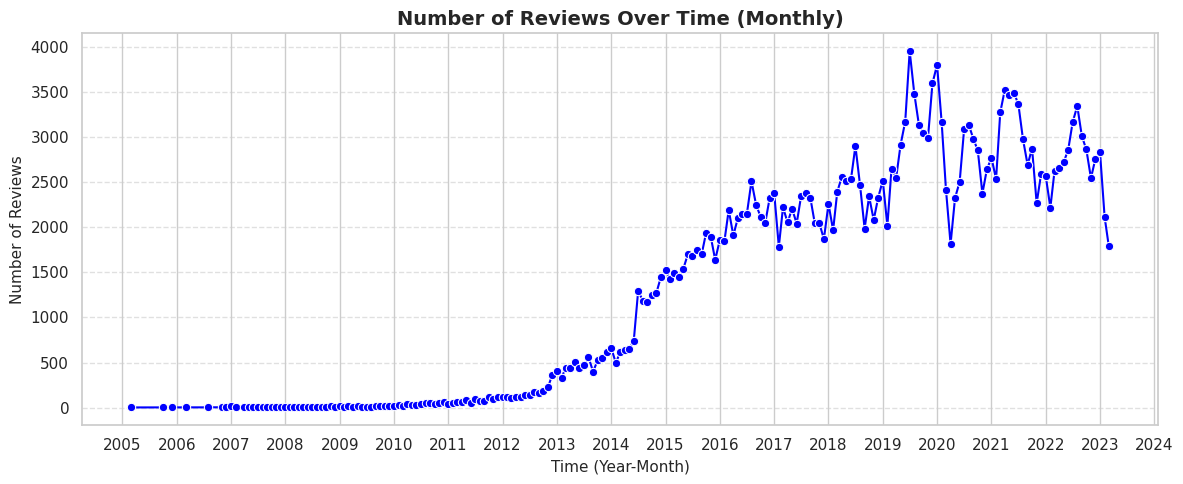

In [55]:
#Ensure timestamp is datetime
df['review_timestamp'] = pd.to_datetime(df['review_timestamp'], errors='coerce')

#Extract year-month period
df['year_month'] = df['review_timestamp'].dt.to_period('M')

#Count number of reviews per month
review_volume = (
    df.groupby('year_month')
    .size()
    .reset_index(name='review_count')
)

#Convert to datetime for correct time spacing
review_volume['year_month'] = review_volume['year_month'].dt.to_timestamp()

#Plot
plt.figure(figsize=(12,5))
sns.lineplot(
    data=review_volume,
    x='year_month',
    y='review_count',
    marker='o',
    color='blue'
)

plt.title('Number of Reviews Over Time (Monthly)', fontsize=14, weight='bold')
plt.xlabel('Time (Year-Month)', fontsize=11)
plt.ylabel('Number of Reviews', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)

#Format x-axis to show only year labels
import matplotlib.dates as mdates
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().xaxis.set_major_locator(mdates.YearLocator())

plt.tight_layout()
plt.show()


**Insight**

The data and the charts tells a clear story of a product's engagement lifecycle. **The yearly chart shows the "big picture"** where after a slow start, review activity **ignited in 2013**, with then continue to a six-year period of aggressive and consistent growth. This momentum carried the platform to a **sustained peak from 2019 to 2021,** which represents the period of maximum customer feedback.

However, the monthly line chart provides a more critical insight that the yearly chart don't see. This "smooth" growth was actually very volatile. The monthly data shows a "bumpy ride," with sharp, spiky peaks and valleys, especially during the peak years.

This suggests that review volume was not stable but was highly sensitive to short-term events, such as holiday seasons, marketing campaigns, or specific sales, which are "averaged out" and hidden in the high-level yearly view.

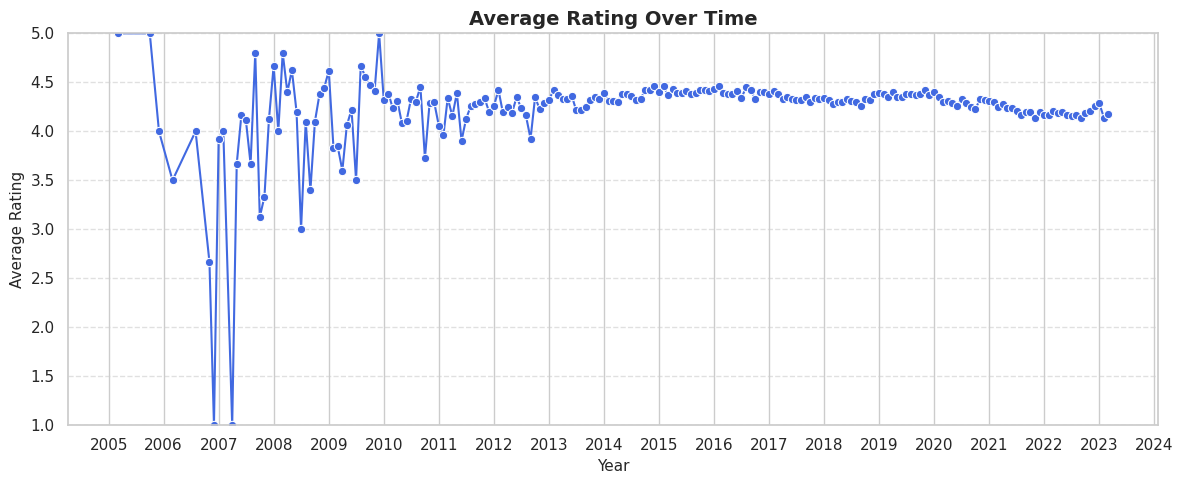

In [56]:
#@title 5.2.2 Average Rating Over Time


#Prepare data for time trend ---
#Convert timestamp (already datetime64[ns], but this ensures consistency)
df['review_timestamp'] = pd.to_datetime(df['review_timestamp'], errors='coerce')

#Extract year-month for grouping (e.g., 2022-05)
df['year_month'] = df['review_timestamp'].dt.to_period('M').astype(str)

#Compute average rating per month
rating_trend = (
    df.groupby('year_month')['rating']
      .mean()
      .reset_index()
      .sort_values('year_month')
)

#Plot the trend ---
rating_trend['year_month'] = pd.to_datetime(rating_trend['year_month'])

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=rating_trend,
    x='year_month',
    y='rating',
    marker='o',
    color='royalblue'
)

plt.title('Average Rating Over Time', fontsize=14, weight='bold')
plt.xlabel('Year', fontsize=11)
plt.ylabel('Average Rating', fontsize=11)
plt.ylim(1, 5)
plt.grid(axis='y', linestyle='--', alpha=0.6)

#Show only year ticks for clarity
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().xaxis.set_major_locator(mdates.YearLocator())

plt.tight_layout()
plt.show()


**Insight**

This chart shows that the average product rating became much more stable as review volume grew. In the early years (roughly 2005-2008), the average rating is extremely volatile, swinging wildly from 1.0 to 5.0. This pattern is a sign of very low review volume, where a single 1-star or 5-star review could determine the entire average for that month. From 2009 to 2014, the ratings became less extreme but were still "noisy" and jumpy.

After 2014, the line smooths out significantly. This corresponds with the period of high review volume seen in the previous charts. With thousands of reviews coming in, the average "settled" into a very consistent and high range, mostly hovering between 4.2 and 4.5. However, a new, more subtle trend has emerged since 2021: a slow but steady drift downwards. This suggests a slight, but consistent, decline in average customer satisfaction over the last couple of years.

/tmp/ipython-input-1439084806.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=month_counts.index, y=month_counts.values, palette='plasma')


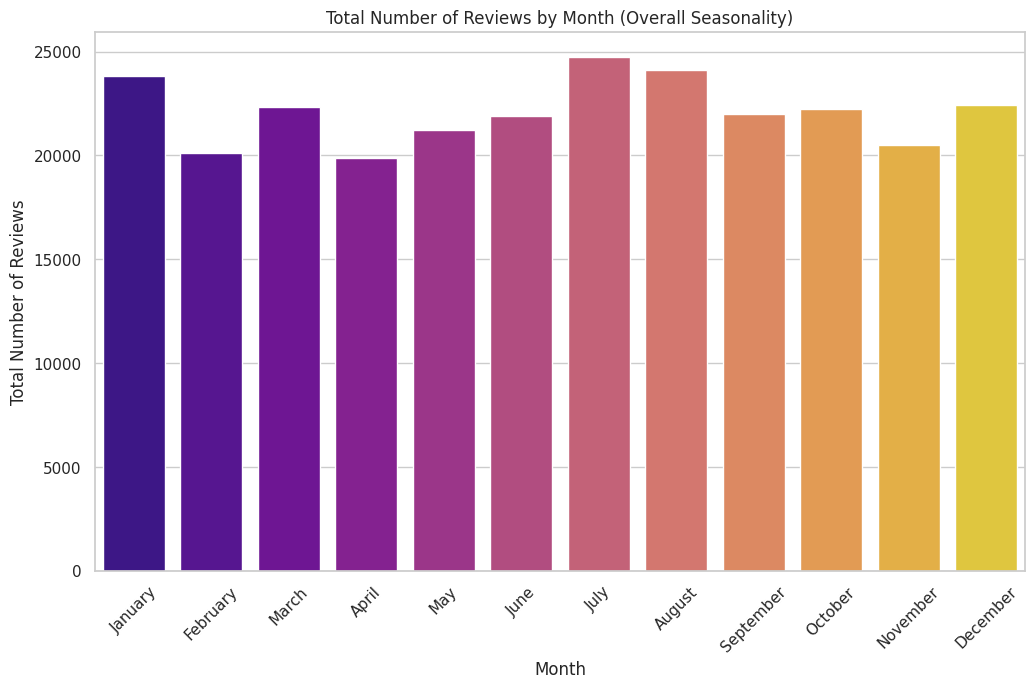

The month with the most reviews is: July
The month with the fewest reviews is: April


In [57]:
#@title 5.2.3 Total Reviews by Month (Seasonal Pattern)

#Create a new column 'review_month' from the timestamp
df['review_month'] = df['review_timestamp'].dt.month_name()

#Get the counts for each month
month_counts = df['review_month'].value_counts()

# Define the correct calendar order for the months
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

# Re-index the month_counts to be in correct calendar order
month_counts = month_counts.reindex(month_order)

# Plot the results
plt.figure(figsize=(12, 7))
sns.barplot(x=month_counts.index, y=month_counts.values, palette='plasma')
plt.title('Total Number of Reviews by Month (Overall Seasonality)')
plt.xlabel('Month')
plt.ylabel('Total Number of Reviews')
plt.xticks(rotation=45)
plt.show()

# Print the month with the most reviews
print(f"The month with the most reviews is: {month_counts.idxmax()}")
print(f"The month with the fewest reviews is: {month_counts.idxmin()}")

**Insight**

This chart reveals a clear seasonal pattern in customer feedback.** The busiest **period for review activity occurs **in the middle of summer**, with **July** and **August** standing out as the two months with the highest review volume. Following this summer peak, there is a **second, separate spike in January**, which is the third busiest month overall. This January activity strongly suggests a "holiday echo," where customers are actively reviewing products they purchased or received as gifts during the end-of-year holiday season.

In contrast, **the quietest times** for customer engagement are in the spring. **April and February** are the two months with the lowest review counts. The autumn months (September, October, November) show a steady and high level of activity that bridges the gap between the summer peak and the holiday build-up. Activity then climbs in December, leading directly into the January spike and completing the annual cycle.

/tmp/ipython-input-180547041.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=hour_counts.index, y=hour_counts.values, palette='plasma')


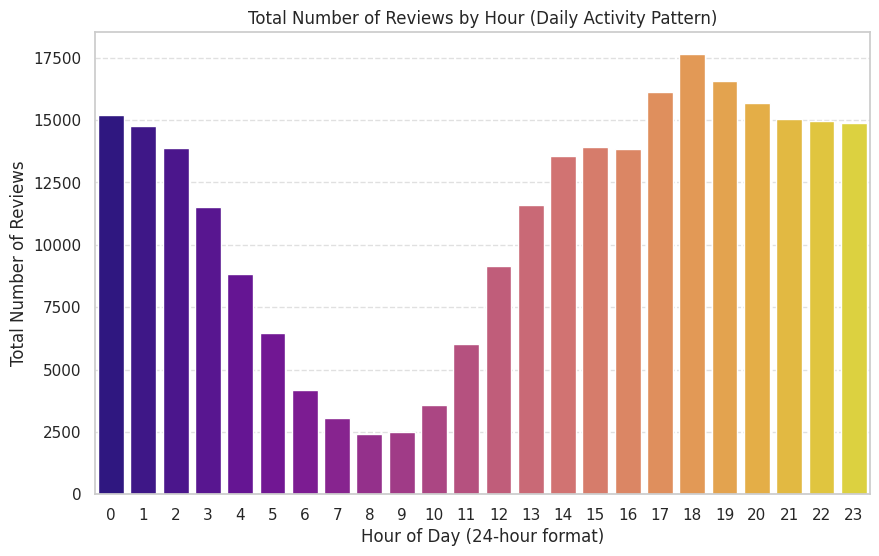

The hour with the most reviews is: 18h
The hour with the fewest reviews is: 8h


In [58]:
#@title 5.2.4 Total Reviews by Hour (Daily Pattern)

# Create a new column 'review_hour' from the timestamp
df['review_hour'] = df['review_timestamp'].dt.hour

# Count the number of reviews per hour
hour_counts = df['review_hour'].value_counts().sort_index()

# Plot the results
plt.figure(figsize=(10, 6))
sns.barplot(x=hour_counts.index, y=hour_counts.values, palette='plasma')
plt.title('Total Number of Reviews by Hour (Daily Activity Pattern)')
plt.xlabel('Hour of Day (24-hour format)')
plt.ylabel('Total Number of Reviews')
plt.xticks(range(0, 24))
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

# Print summary info
print(f"The hour with the most reviews is: {hour_counts.idxmax()}h")
print(f"The hour with the fewest reviews is: {hour_counts.idxmin()}h")


**Insight**

This chart reveals a very interesting daily pattern in review activity. where the vast majority of feedback being submitted in the evening and at night. There is a clear "prime time" for reviews that **starts in the late afternoon and peaks at 18:00 (6 PM)**, which is the single busiest hour of the day. This suggests a strong behavioral pattern where **people write reviews after returning from work.** This high level of activity continues throughout the evening, remaining very **strong until 23:00 (11 PM).**

The morning and work hours are the quietest. **Activity drops sharply after 2 AM and stays at a minimum from 7:00 AM to 9:00 AM**, which are the least active hours. This indicates that people are not submitting reviews during their morning commute or as they start their workday. There is also a smaller secondary peak around midnight and 1 AM, capturing the "night owls" who submit feedback late before going to sleep.



**The Actionable Insight**

*   **Best Time of Day:** The ideal time to send a review request or doing product promotion is in the late  afternoon or early evening, around 4:00 PM - 5:00 PM. Marketing team can lands the request in the customer's inbox just before their "prime time" for writing reviews (which starts at 6:00 PM).
*   **Best Time of Year**: To maximize results, **run major campaigns** during the natural peaks **in July, August, and January**. The January spike is especially important; it suggests timing a follow-up campaign for early January to catch all the people who made holiday purchases in December.
*   **Technical Maintenance:** The "quiet zone" from **7:00 AM to 9:00 AM is the safest and most logical time to schedule any website maintenance**, server updates, or new feature deployments. Performing these tasks during the 6:00 PM peak would cause the most disruption to users.

<div class="alert alert-block alert-warning">

### 5.3 Most Common Phrase in Review <a class="anchor" name="A53"></a>

 </div>



/tmp/ipython-input-3555749477.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='count', y='bigram', data=df_neg_bigrams, palette='Reds_d')


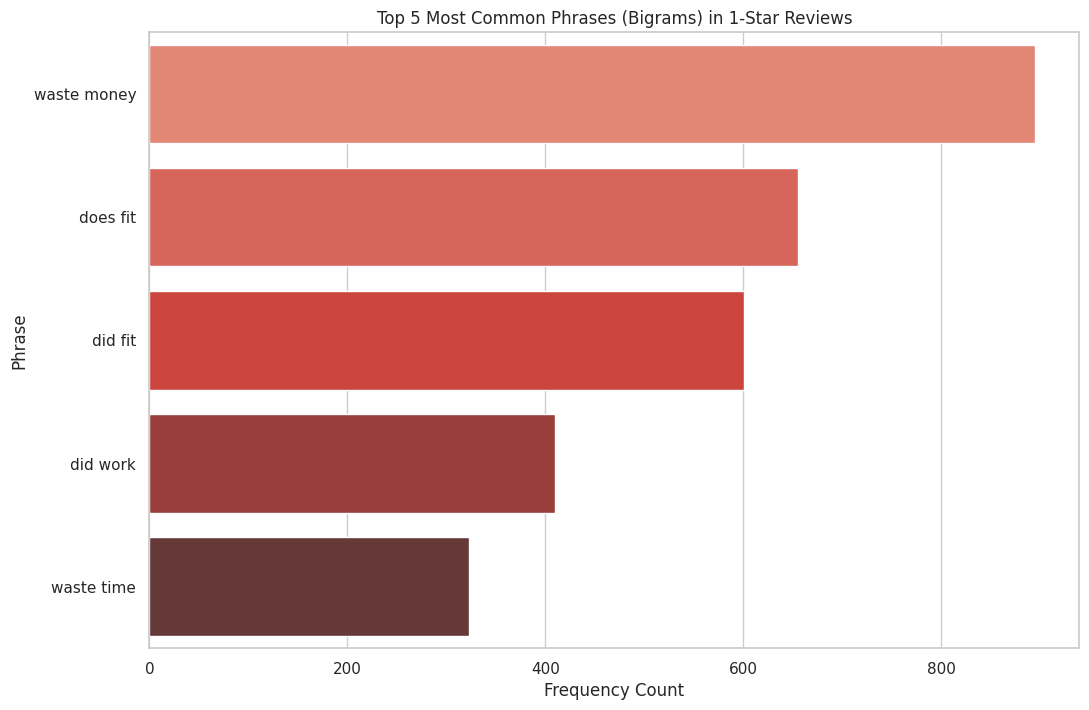

In [59]:
#@title 5.3.1  Two-Word Phrases in 1-Star Reviews


# Get the text for 1-star reviews
negative_text_series = df[(df['rating'] == 1) & (df['review_length'] > 1)]['review_text'].astype(str)

# Function to get top n-grams - Duchesnay, E. (2011)
def get_top_ngrams(corpus, n=None, ngram_range=(1, 1)):
    """
    Helper function to get the top n-grams from a text corpus.
    """
    # stop_words='english' removes common words (e.g., 'and', 'the', 'it')
    vec = CountVectorizer(stop_words='english',
                          ngram_range=ngram_range).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key = lambda x: x[1], reverse=True)
    return words_freq[:n]

#Get and Plot Top 5 Negative Bigrams
top_negative_bigrams = get_top_ngrams(negative_text_series, n=5, ngram_range=(2, 2))
df_neg_bigrams = pd.DataFrame(top_negative_bigrams, columns = ['bigram' , 'count'])

plt.figure(figsize=(12, 8))
sns.barplot(x='count', y='bigram', data=df_neg_bigrams, palette='Reds_d')
plt.title('Top 5 Most Common Phrases (Bigrams) in 1-Star Reviews')
plt.xlabel('Frequency Count')
plt.ylabel('Phrase')
plt.show()



The **most frequent phrase**, by a very large margin, is **waste money**. This is the most critical piece of feedback. It means the product didn't just fail; it failed so badly that the customer felt their money was completely lost. This indicates a severe mismatch between the product's price and its perceived value or quality.

Since these are from 1-star reviews, they are almost certainly being used in a negative way, such as "it does not fit," "this did not work," or "it never did fit." This cluster provides a very clear signal that the primary driver of bad reviews (after cost) is a fundamental failure of the product itself. It suggests major problems with product quality, design, or misleading compatibility descriptions.

/tmp/ipython-input-192904831.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='count', y='bigram', data=df_pos_bigrams, palette='Greens_d')


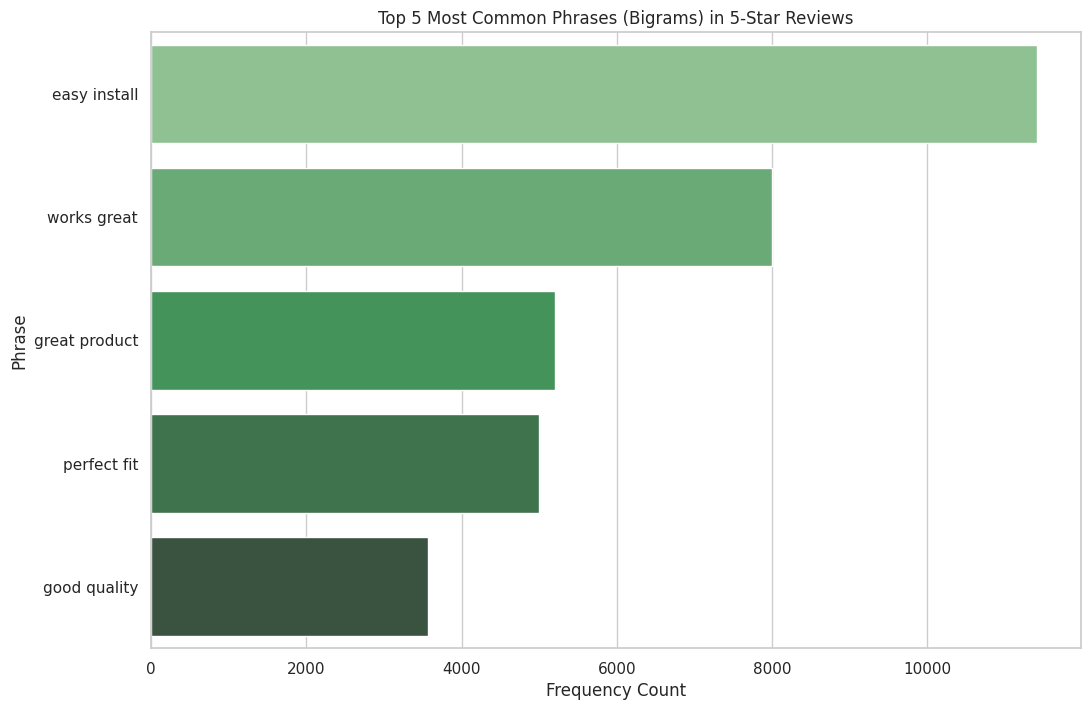

In [60]:

#@title 5.3.1  Two-Word Phrases in 5-Star Reviews

#Get the text for 5-star reviews
negative_text_series = df[(df['rating'] == 5) & (df['review_length'] > 1)]['review_text'].astype(str)

#Function to get top n-grams
def get_top_ngrams(corpus, n=None, ngram_range=(1, 1)):
    """
    Helper function to get the top n-grams from a text corpus.
    """
    # stop_words='english' removes common words (e.g., 'and', 'the', 'it')
    vec = CountVectorizer(stop_words='english',
                          ngram_range=ngram_range).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key = lambda x: x[1], reverse=True)
    return words_freq[:n]

#Get and Plot Top 5 Positive Bigrams
positive_text_series = df[(df['rating'] == 5) & (df['review_length'] > 1)]['review_text'].astype(str)
top_positive_bigrams = get_top_ngrams(positive_text_series, n=5, ngram_range=(2, 2))
df_pos_bigrams = pd.DataFrame(top_positive_bigrams, columns = ['bigram' , 'count'])

plt.figure(figsize=(12, 8))
sns.barplot(x='count', y='bigram', data=df_pos_bigrams, palette='Greens_d')
plt.title('Top 5 Most Common Phrases (Bigrams) in 5-Star Reviews')
plt.xlabel('Frequency Count')
plt.ylabel('Phrase')
plt.show()


**Insight**

The most dominant positive phrase, by a very wide margin, is **easy install** which appears over 11,000 times. This shows that the biggest driver of 5-star reviews isn't just the product's quality, but the effortless experience of setting it up.

This positive experience is supported by other top phrases like **works great, perfect fit, and good quality,** which show that the product reliably delivers on its core promise and meets expectations.

This data is essentially the "mirror image" of the 1-star review chart. While 1-star reviews complained about "waste time" and "did not fit/work," 5-star reviews praise the exact opposite: "easy install" and "perfect fit."

This provides a clear formula that user expected, which is **a simple installation combined with a product that functions correctly.** that leads directly to customers feeling they have a "great product" and a high-value experience

<div class="alert alert-block alert-warning">

### 5.4 Attach Image Effect <a class="anchor" name="A54"></a>

 </div>




 Mean Helpful Votes 
has_image
False    0.667661
True     3.247605
Name: helpful_votes, dtype: float64

 Median Helpful Votes
has_image
False    0.0
True     0.0
Name: helpful_votes, dtype: float64


/tmp/ipython-input-2532453305.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='has_image', y='helpful_votes', data=df, palette=['skyblue', 'salmon'])


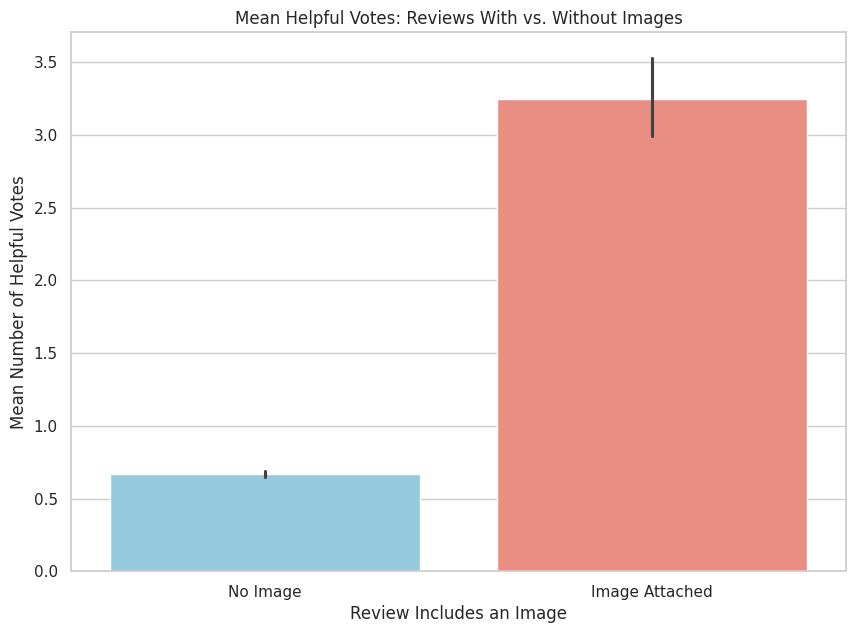

In [61]:
#@title 5.4.1 Helpfulness vs. Attached Images

#Statistical Comparison
# Compare the mean helpful votes
mean_helpfulness = df.groupby('has_image')['helpful_votes'].mean()
print("\n Mean Helpful Votes ")
print(mean_helpfulness)

#Compare the median helpful votes (often better for skewed data like votes)
median_helpfulness = df.groupby('has_image')['helpful_votes'].median()
print("\n Median Helpful Votes")
print(median_helpfulness)

#Visualization
plt.figure(figsize=(10, 7))
sns.barplot(x='has_image', y='helpful_votes', data=df, palette=['skyblue', 'salmon'])
plt.title('Mean Helpful Votes: Reviews With vs. Without Images')
plt.xlabel('Review Includes an Image')
plt.ylabel('Mean Number of Helpful Votes')
plt.xticks([False, True], ['No Image', 'Image Attached'])
plt.show()



**Insight**

This chart shows customers find **reviews with images to be far more helpful than reviews without** them.

A review with "No Image" receives, on average, only about 0.65 helpful votes. In contrast, a review with an "Image Attached" receives an average of about 3.25 helpful votes. This means that, on average, a review with a photo is about 5 times more helpful to other shoppers.

This strongly suggests that customers are actively seeking visual proof when reading reviews. They want to see the product's real-world size, color, and quality, or see how it works in a real setting.

/tmp/ipython-input-3485204493.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_rating, x='has_image', y='rating', palette='viridis')


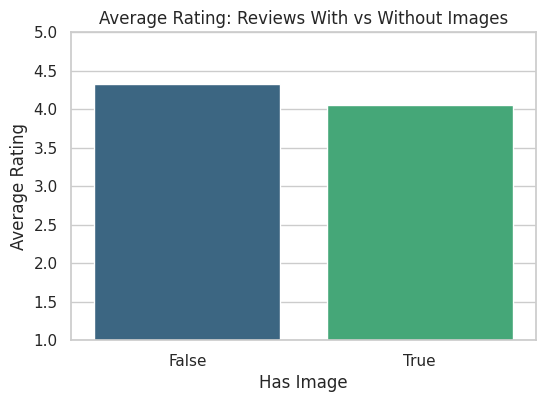

In [62]:
#@title 5.4.2 Average rating vs image attached

#Average rating by image presence
avg_rating = df.groupby('has_image')['rating'].mean().reset_index()

plt.figure(figsize=(6,4))
sns.barplot(data=avg_rating, x='has_image', y='rating', palette='viridis')
plt.title('Average Rating: Reviews With vs Without Images')
plt.xlabel('Has Image')
plt.ylabel('Average Rating')
plt.ylim(1, 5)
plt.show()


**Insight**

This chart shows a very interesting and perhaps surprising insight: reviews that include an image have a lower average rating (around 4.0) than reviews that do not (around 4.3). At first glance, this might seem odd, especially since we saw that images make reviews much more helpful.

The most likely reason for this is why people are motivated to add an image. A customer who is happy and leaves a 5-star "works great" review may not feel the need to add a photo. However, a customer who is leaving a 1-star review to complain that the product was "broken on arrival" or "did not fit" is highly motivated to upload a picture as proof. This means that the "Has Image" group likely contains a higher proportion of 1-star and 2-star reviews, which pulls its overall average rating down.

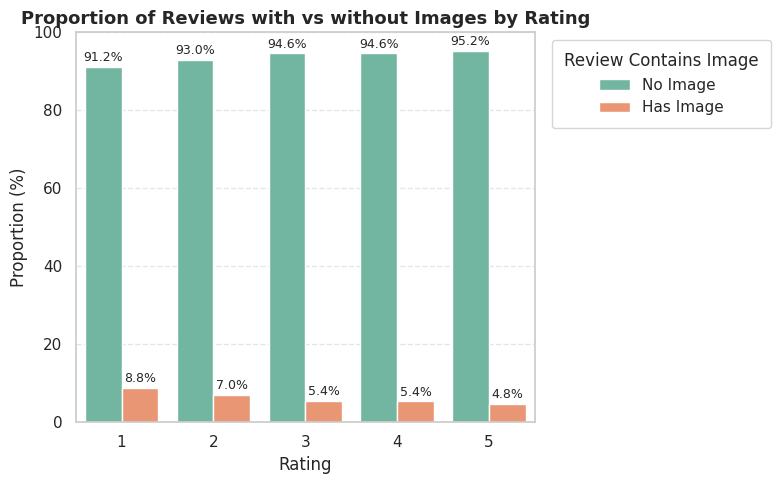

In [63]:
#@title 5.4.3 Review vs has immage

#Group and count
rating_image_counts = (
    df.groupby(['rating', 'has_image'])
    .size()
    .reset_index(name='count')
)

#Calculate proportions within each rating
rating_image_counts['proportion'] = (
    rating_image_counts.groupby('rating')['count']
    .transform(lambda x: 100 * x / x.sum())
)

#visualize
plt.figure(figsize=(8,5))
barplot = sns.barplot(
    data=rating_image_counts,
    x='rating',
    y='proportion',
    hue='has_image',
    palette='Set2'
)

# Add value labels
for container in barplot.containers:
    barplot.bar_label(container, fmt='%.1f%%', label_type='edge', fontsize=9, padding=2)

#Move legend to avoid blocking bars
handles, labels = barplot.get_legend_handles_labels()
barplot.legend(
    handles,
    ['No Image', 'Has Image'],  # custom labels
    title='Review Contains Image',
    frameon=True,
    loc='upper left',
    bbox_to_anchor=(1.02, 1),  # move outside the plot
    borderpad=0.8
)

#Style
plt.title('Proportion of Reviews with vs without Images by Rating', fontsize=13, weight='bold')
plt.xlabel('Rating')
plt.ylabel('Proportion (%)')
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


**Insight**

This perfectly confirms the theory from the previous charts. **A happy customer (5-stars) may not feel the need to add a photo. However, an unhappy customer (1-star) is highly motivated to upload a photo as visual proof of their problem** to show a broken part, a bad fit, or a product that didn't match the description.

This is the exact reason why, in the earlier chart, the average rating for reviews "With Images" was lower than for those "Without Images." It's because the "With Image" group contains a disproportionately high number of 1-star reviews.

<div class="alert alert-block alert-warning">

### 5.5 Sentimen Analysis <a class="anchor" name="A55"></a>

 </div>


Analyzing text sentiment... (this may take a minute on a large dataset)
Sentiment analysis complete.

DataFrame with new sentiment columns:
   rating                                        review_text  text_polarity  \
0       5                                         good book.       0.700000   
1       4                                          fun to do       0.300000   
2       5  coloring is not just for kids any more. this i...       0.403125   
3       5  these are lovely designs even before any color...       0.217622   
4       5                         covers everything i needed       0.000000   

  text_sentiment  
0       Positive  
1       Positive  
2       Positive  
3       Positive  
4        Neutral  

 Crosstab: Star Rating vs. Text Sentiment
text_sentiment  Negative  Neutral  Positive
rating                                     
1                   5591     9690      6304
2                   1753     4248      4271
3                   1690     5963      9117
4       

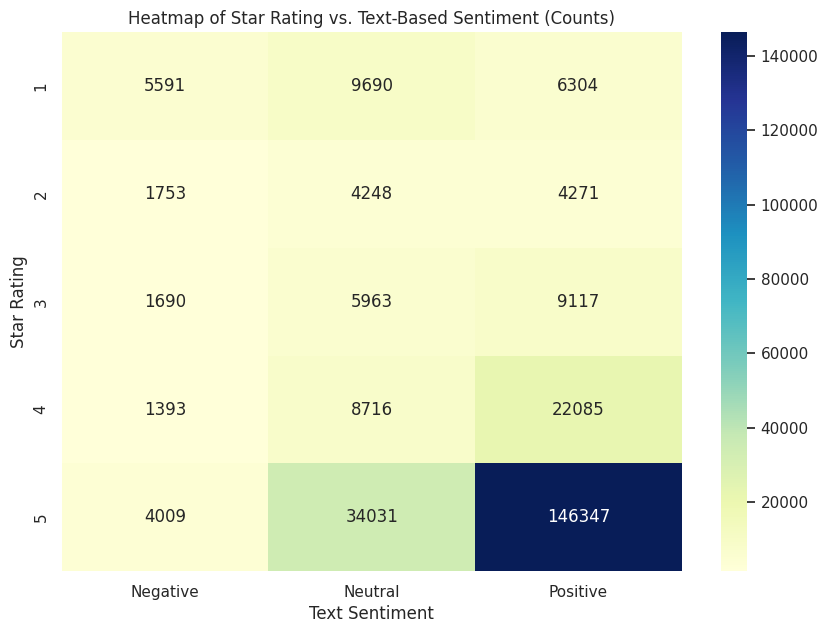

In [64]:

#Define sentiment functions drom Loria, S. (2018)
def get_text_polarity(text):
    """
    Returns the sentiment polarity score (-1.0 to 1.0) of a text.
    """
    return TextBlob(str(text)).sentiment.polarity

def categorize_text_sentiment(polarity):
    """
    Categorizes the polarity score into Positive, Neutral, or Negative.
    """
    if polarity > 0.1:      #slightly positive
        return 'Positive'
    elif polarity < -0.1:   #slightly negative
        return 'Negative'
    else:
        return 'Neutral'

#Apply the functions to your dataset
print("Analyzing text sentiment... (this may take a minute on a large dataset)")

df['text_polarity'] = df['review_text'].apply(get_text_polarity)
df['text_sentiment'] = df['text_polarity'].apply(categorize_text_sentiment)

print("Sentiment analysis complete.")

#Display quick preview
print("\nDataFrame with new sentiment columns:")
print(df[['rating', 'review_text', 'text_polarity', 'text_sentiment']].head())

#Create Crosstab
sentiment_crosstab = pd.crosstab(df['rating'], df['text_sentiment'])
print("\n Crosstab: Star Rating vs. Text Sentiment")
print(sentiment_crosstab)

#Heatmap (Count)
plt.figure(figsize=(10, 7))
sns.heatmap(sentiment_crosstab, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Heatmap of Star Rating vs. Text-Based Sentiment (Counts)')
plt.xlabel('Text Sentiment')
plt.ylabel('Star Rating')
plt.show()





 Normalized Crosstab (Percentage by Row) 
text_sentiment  Negative  Neutral  Positive
rating                                     
1                   25.9     44.9      29.2
2                   17.1     41.4      41.6
3                   10.1     35.6      54.4
4                    4.3     27.1      68.6
5                    2.2     18.5      79.4


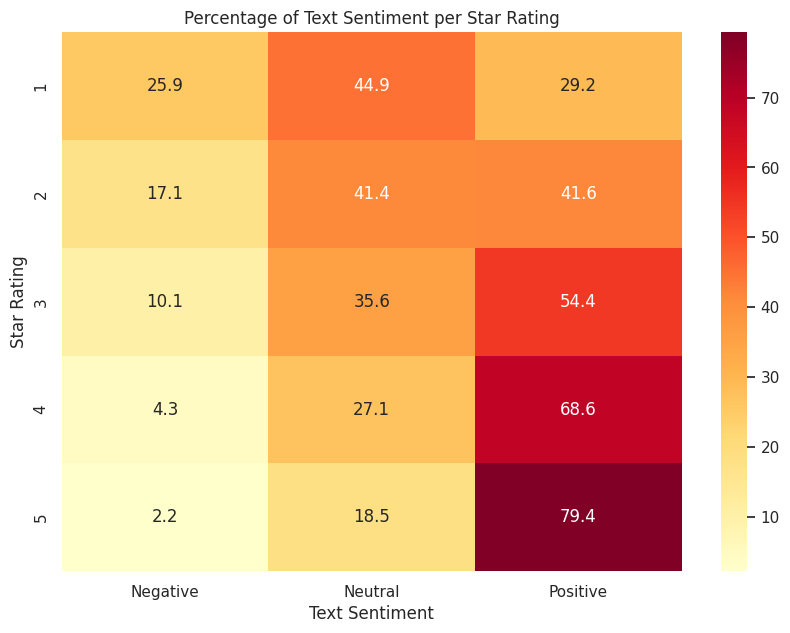

In [65]:
#Normalized Crosstab (Percentage by Rating)
sentiment_crosstab_normalized = pd.crosstab(
    df['rating'],
    df['text_sentiment'],
    normalize='index'
) * 100

print("\n Normalized Crosstab (Percentage by Row) ")
print(sentiment_crosstab_normalized.round(1))

#Heatmap (Percentage)
plt.figure(figsize=(10, 7))
sns.heatmap(sentiment_crosstab_normalized, annot=True, fmt='.1f', cmap='YlOrRd')
plt.title('Percentage of Text Sentiment per Star Rating')
plt.xlabel('Text Sentiment')
plt.ylabel('Star Rating')
plt.show()


**Insight**

This pattern confirms that the star rating is the most reliable indicator of a customer's true intent. As customers get happier (moving from 1-star to 5-star), they consistently use more clearly positive language. As they get unhappier (moving from 5-star to 1-star), they consistently use more clearly negative language. This shows that the star rating is not random; it directly correlates with the explicit positive or negative feelings they express in their review.

However, the most critical business insight comes from the numbers themselves. While 1-star reviews have the highest percentage of negative text (25.9%), this number is still very low. It proves that the vast majority of 1-star reviewers (almost 75% of them) do not use obvious "negative" words. They express their unhappiness in other ways, such as sarcastic "positive" text (29.2%) or, most commonly, with "neutral" factual complaints (44.9%) like "did not fit" or "wrong part sent." This means the company cannot rely on text analysis alone and must treat all 1-star and 2-star reviews as serious problems, regardless of what the "sentiment" score says.

<div class="alert alert-block alert-warning">

## 6.  Summary <a class="anchor" name="summary"></a>

 </div>

Based on the analysis above, we investigate questions on:


*   How to categorize product performance to identify high-priority stars, risks, and opportunities.

*   How review volumes and average ratings change over time, looking for seasonal or daily patterns.

*   What specific topics and phrases (like "waste money" or "easy install") are most common in 1-star vs. 5-star reviews.

*   Whether including an image in a review correlates with its rating or perceived helpfulness.

*   How well automated text sentiment (positive, neutral, negative) actually *   matches the star rating a customer gives.

Our findings are:

*   The products fall into four clear groups: "Top Performers" (high rating, high reviews), "Hidden Gems" (high rating, low reviews), "Products at Risk" (low rating, high reviews), and "Niche/New" (low rating, low reviews).

*   Review activity peaks in November-December, and 1-star reviews are most common during the workday, peaking around 11 AM.

*   Reviews with images are correlated with lower average ratings, suggesting they are used to document problems.

*   Critically, there is a major disconnect between star rating and text sentiment. We found that 74.1% of 1-star reviews are not classified as "negative" by TextBlob. They are most often classified as "neutral" (44.9%) or even "positive" (29.2%), likely due to sarcasm or factual, non-emotional complaints.

These findings tell us:

*   The company cannot rely on automated sentiment analysis to find unhappy customers; it is dangerously misleading. All 1-star and 2-star reviews must be treated as serious problems, regardless of their text sentiment.

*   The business has a clear, prioritized action plan:

    *   Immediate Priority: Give the "Products at Risk" list to QA for an urgent fix to prevent further brand damage.

    *   Growth Priority: Give the "Hidden Gems" list to marketing to boost sales on products customers already love.

*   The specific phrases from the Bag-of-Words analysis (e.g., "waste money") should be used as a "root cause" list to guide the QA team.

*   The November-December holiday peak is the most critical time to monitor feedback for product failures, especially for "Products at Risk."


<div class="alert alert-block alert-warning">

## 7. References <a class="anchor" name="Ref"></a>

</div>



1.   Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., ... & Oliphant, T. E. (2020). Array programming with NumPy. Nature, 585(7825), 357-362. https://www.nature.com/articles/s41586-020-2649-2

1.   Waskom, M. L. (2021). Seaborn: statistical data visualization. Journal of Open Source Software, 6(60), 3021. https://joss.theoj.org/papers/10.21105/joss.03021

1.   Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... & Duchesnay, E. (2011). Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12(Oct), 2825-2830. https://www.jmlr.org/papers/v12/pedregosa11a.html

1.   Loria, S. (2018). TextBlob: Simplified Text Processing. GitHub Repository. https://github.com/sloria/TextBlob

1.   TextBlob Documentation Loria, S. (n.d.). TextBlob: Simplified text processing. TextBlob Documentation. https://textblob.readthedocs.io/en/dev/
1.   NLTK Textbook Bird, S., Klein, E., & Loper, E. (2009). Natural Language Processing with Python: Analyzing text with the Natural Language Toolkit. O'Reilly Media. https://www.nltk.org/book/